<a href="https://colab.research.google.com/github/hasan2733/artificial-intelligence/blob/main/Notebooks/Implementation/Cardiovascular_disease_Prediction_with_AutoML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install tpot

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 2.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 215.1/215.1 kB 11.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.6/117.6 kB 13.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 24.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.2/86.2 kB 9.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 30.5 MB/s eta 0:00:00
  Created wheel for func-timeout: filename=func_timeout-4.3.5-py3-none-any.whl size=15160 sha256=0725b26f0d50e19bf507e2a29a2eb61de112737d14a738a82317f7c6b3538915
  Stored in directory: /root/.cache/pip/wheels/2a/5b/5a/f0265ca0122db89c4a9381bd442bbc09de72077ea713791cbe
  Created wheel for stopit: filename=stopit-1.1.2-py3-none-any.whl size=11986 sha256=9b06

In [2]:
# Import necessary libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc, matthews_corrcoef, log_loss, f1_score
from tpot import TPOTClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.ensemble import VotingClassifier, RandomForestClassifier
from sklearn.neural_network import MLPClassifier
# Final Steps: Display Accuracy Results & Evaluate Fusion Model**

# Import necessary visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from imblearn.over_sampling import SMOTE

/usr/local/lib/python3.13/dist-packages/stopit/__init__.py:10: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [3]:
from google.colab import files

uploaded = files.upload()

Saving heart.csv to heart.csv


In [4]:
# Load the dataset
df = pd.read_csv("heart.csv")

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [6]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [7]:
df.isna().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [8]:
# Feature Selection
X = df.drop(columns=['target'])  # Features
y = df['target']  # Labels

In [9]:
X.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2


In [10]:
y

,target
0,0
1,0
2,0
3,0
4,0
...,...
1020,1
1021,0
1022,0
1023,1


In [11]:
# Split dataset into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [12]:
# Apply Feature Scaling (StandardScaler)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)  # Use same scaler for test set

In [13]:
# **Step 3: Apply Jittering (Adding Noise to Features)**
noise_level = 0.02  # Adjust for different noise levels
X_train_noisy = X_train_scaled + np.random.normal(0, noise_level, X_train_scaled.shape)

In [14]:
# **Step 4: Apply SMOTE for Data Balancing (Synthetic Data Generation)**
smote = SMOTE(sampling_strategy='auto', random_state=42)  # Auto mode balances classes equally
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_noisy, y_train)

In [15]:
# **Step 5: Apply Polynomial Feature Expansion**
poly = PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)
X_train_poly = poly.fit_transform(X_train_balanced)
X_test_poly = poly.transform(X_test_scaled)  # Apply same transformation to test set

In [16]:
# **Run TPOT AutoML to Find Best Base Models**
tpot = TPOTClassifier(
    generations=3,  # Reduce for faster execution
    population_size=10,  # Reduce to prevent excessive overfitting
    random_state=42,
    n_jobs=2  # Optimize processing speed
)

# Fit TPOT on training data
tpot.fit(X_train_poly, y_train_balanced)

/usr/local/lib/python3.13/dist-packages/tpot/tpot_estimator/estimator.py:458: UserWarning: Both generations and max_time_mins are set. TPOT will terminate when the first condition is met.
  warnings.warn("Both generations and max_time_mins are set. TPOT will terminate when the first condition is met.")
INFO:distributed.http.proxy:To route to workers diagnostics web server please install jupyter-server-proxy: python -m pip install jupyter-server-proxy
INFO:distributed.scheduler:State start
INFO:distributed.scheduler:  Scheduler at:     tcp://127.0.0.1:40189
INFO:distributed.scheduler:  dashboard at:  http://127.0.0.1:8787/status
INFO:distributed.scheduler:Registering Worker plugin shuffle
INFO:distributed.nanny:        Start Nanny at: 'tcp://127.0.0.1:32985'
INFO:distributed.nanny:        Start Nanny at: 'tcp://127.0.0.1:37777'
INFO:distributed.scheduler:Register worker addr: tcp://127.0.0.1:40117 name: 1
INFO:distributed.scheduler:Starting worker compute stream, tcp://127.0.0.1:40117
I

TPOTClassifier(n_jobs=2, random_state=42,
               search_space=<tpot.search_spaces.pipelines.sequential.SequentialPipeline object at 0x7bd2a27fef90>)

In [17]:
# Get the best model found by TPOT
best_tpot_model = tpot.fitted_pipeline_

In [18]:
# Compute TPOT Accuracy Metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, log_loss, matthews_corrcoef

# Generate predictions
tpot_train_preds = tpot.predict(X_train_poly)
tpot_test_preds = tpot.predict(X_test_poly)

# Compute Accuracy
tpot_train_acc = accuracy_score(y_train_balanced, tpot_train_preds)
tpot_test_acc = accuracy_score(y_test, tpot_test_preds)

# Compute Precision, Recall, F1-score
tpot_precision = precision_score(y_test, tpot_test_preds)
tpot_recall = recall_score(y_test, tpot_test_preds)
tpot_f1 = f1_score(y_test, tpot_test_preds)

# Compute MCC (Matthews Correlation Coefficient)
tpot_mcc = matthews_corrcoef(y_test, tpot_test_preds)

# Compute ROC-AUC
tpot_auc = roc_auc_score(y_test, tpot_test_preds)

# Compute Log Loss (Only if using probabilities)
tpot_test_probs = tpot.predict_proba(X_test_poly)[:, 1]  # Get probability estimates
tpot_logloss = log_loss(y_test, tpot_test_probs)

# Print TPOT Model Accuracy Metrics
print("TPOT AutoML Accuracy Metrics:")
print(f"Train Accuracy: {tpot_train_acc:.4f}")
print(f"Test Accuracy: {tpot_test_acc:.4f}")
print(f"Precision: {tpot_precision:.4f}")
print(f"Recall: {tpot_recall:.4f}")
print(f"F1-Score: {tpot_f1:.4f}")
print(f"MCC: {tpot_mcc:.4f}")
print(f"AUC Score: {tpot_auc:.4f}")
print(f"Log Loss: {tpot_logloss:.4f}")

TPOT AutoML Accuracy Metrics:
Train Accuracy: 0.9973
Test Accuracy: 0.9740
Precision: 0.9862
Recall: 0.9597
F1-Score: 0.9728
MCC: 0.9483
AUC Score: 0.9736
Log Loss: 0.0727


In [19]:
# Reduce complexity of tree-based models
xgb_model = XGBClassifier(
    use_label_encoder=False, eval_metric='logloss',
    max_depth=2,  # Decrease tree depth to prevent overfitting
    learning_rate=0.01,  # Lower learning rate for better convergence
    n_estimators=30,  # Reduce boosting rounds
    reg_alpha=5.0,  # Stronger L1 regularization (feature selection)
    reg_lambda=6.0,  # Stronger L2 regularization (prevents overfitting)
    subsample=0.7,  # Reduce subsample to force diversity
    colsample_bytree=0.7,  # Feature subsampling to reduce variance
    random_state=42
)
lgbm_model = LGBMClassifier(
    max_depth=2,  # Keep trees shallow
    learning_rate=0.01,
    n_estimators=30,
    reg_alpha=5.0,
    reg_lambda=6.0,
    subsample=0.7,
    colsample_bytree=0.7,
    random_state=42
)

In [20]:
fusion_model = VotingClassifier(
    estimators=[('xgb', xgb_model), ('lgbm', lgbm_model), ('tpot', best_tpot_model)],
    voting='soft',
    weights=[0.3, 0.3, 0.4]  # Prioritize TPOT-selected model
)
fusion_model.fit(X_train_poly, y_train_balanced)

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [14:08:02] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


[LightGBM] [Info] Number of positive: 377, number of negative: 377
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001183 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 22901
[LightGBM] [Info] Number of data points in the train set: 754, number of used features: 91
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits wi

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


VotingClassifier(estimators=[('xgb',
                              XGBClassifier(base_score=None, booster=None,
                                            callbacks=None,
                                            colsample_bylevel=None,
                                            colsample_bynode=None,
                                            colsample_bytree=0.7, device=None,
                                            early_stopping_rounds=None,
                                            enable_categorical=True,
                                            eval_metric='logloss',
                                            feature_types=None,
                                            feature_weights=None, gamma=None,
                                            grow_policy=None,
                                            importance_type=None,
                                            interaction_cons...
                                               FeatureUnion(transformer_list=[('skiptransformer',
                                                                               SkipTransformer()),
                                                                              ('passthrough',
                                                                               Passthrough())])),
                                              ('mlpclassifier',
                                               MLPClassifier(activation=np.str_('logistic'),
                                                             alpha=0.0038575724846,
                                                             early_stopping=np.False_,
                                                             hidden_layer_sizes=[290,
                                                                                 290,
                                                                                 290],
                                                             learning_rate=np.str_('constant'),
                                                             learning_rate_init=0.0081915459426,
                                                             n_iter_no_change=32,
                                                             random_state=42))]))],
                 voting='soft', weights=[0.3, 0.3, 0.4])

In [21]:
from sklearn.calibration import CalibratedClassifierCV
# **Calibrate Probabilities for Fusion Model (XGBoost + LightGBM + TPOT)**
fusion_model_calibrated = CalibratedClassifierCV(fusion_model, method='sigmoid', cv=5)
fusion_model_calibrated.fit(X_train_poly, y_train_balanced)

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [14:09:03] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


[LightGBM] [Info] Number of positive: 301, number of negative: 302
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000761 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 18322
[LightGBM] [Info] Number of data points in the train set: 603, number of used features: 91
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.499171 -> initscore=-0.003317
[LightGBM] [Info] Start training from score -0.003317
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, be

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [14:09:11] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


[LightGBM] [Info] Number of positive: 301, number of negative: 302
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002862 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 18321
[LightGBM] [Info] Number of data points in the train set: 603, number of used features: 91
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.499171 -> initscore=-0.003317
[LightGBM] [Info] Start training from score -0.003317
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, be

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [14:09:27] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


...

[LightGBM] [Info] Number of positive: 302, number of negative: 301
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001082 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 18311
[LightGBM] [Info] Number of data points in the train set: 603, number of used features: 91
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500829 -> initscore=0.003317
[LightGBM] [Info] Start training from score 0.003317
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [14:09:53] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


[LightGBM] [Info] Number of positive: 302, number of negative: 302
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001112 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 18355
[LightGBM] [Info] Number of data points in the train set: 604, number of used features: 91
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits wi

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


CalibratedClassifierCV(cv=5,
                       estimator=VotingClassifier(estimators=[('xgb',
                                                               XGBClassifier(base_score=None,
                                                                             booster=None,
                                                                             callbacks=None,
                                                                             colsample_bylevel=None,
                                                                             colsample_bynode=None,
                                                                             colsample_bytree=0.7,
                                                                             device=None,
                                                                             early_stopping_rounds=None,
                                                                             enable_categorical=True,
                                                                             eval_metric='logloss',
                                                                             feature_types=None,
                                                                             feature_weights=None,
                                                                             gamma=None,
                                                                             grow_policy=None...
                                                                                FeatureUnion(transformer_list=[('skiptransformer',
                                                                                                                SkipTransformer()),
                                                                                                               ('passthrough',
                                                                                                                Passthrough())])),
                                                                               ('mlpclassifier',
                                                                                MLPClassifier(activation=np.str_('logistic'),
                                                                                              alpha=0.0038575724846,
                                                                                              early_stopping=np.False_,
                                                                                              hidden_layer_sizes=[290,
                                                                                                                  290,
                                                                                                                  290],
                                                                                              learning_rate=np.str_('constant'),
                                                                                              learning_rate_init=0.0081915459426,
                                                                                              n_iter_no_change=32,
                                                                                              random_state=42))]))],
                                                  voting='soft',
                                                  weights=[0.3, 0.3, 0.4]))

In [22]:
# **Step 8: Train Meta-Learner (MLP + RF with Regularization)**
meta_learner_rf = RandomForestClassifier(n_estimators=80, max_depth=3, random_state=42)
from sklearn.calibration import CalibratedClassifierCV

meta_learner_mlp_finetuned = MLPClassifier(
    hidden_layer_sizes=(20,),
    activation='relu',
    solver='adam',
    alpha=5.0,  # Increase L2 regularization to prevent memorization
    learning_rate='adaptive',
    max_iter=1500,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=42
)

In [23]:
# **Re-Train Meta-Learner (MLP + RF with Fine-Tuned MLP)**
meta_learner_ensemble_finetuned = VotingClassifier(
    estimators=[('mlp', meta_learner_mlp_finetuned), ('rf', meta_learner_rf)],
    voting='soft'
)

In [25]:
train_fusion_preds_calibrated = fusion_model_calibrated.predict_proba(X_train_poly)

# **Train Meta-Learner with Updated Predictions**
meta_learner_ensemble_finetuned.fit(train_fusion_preds_calibrated, y_train_balanced)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


VotingClassifier(estimators=[('mlp',
                              MLPClassifier(alpha=5.0, early_stopping=True,
                                            hidden_layer_sizes=(20,),
                                            learning_rate='adaptive',
                                            max_iter=1500, random_state=42)),
                             ('rf',
                              RandomForestClassifier(max_depth=3,
                                                     n_estimators=80,
                                                     random_state=42))],
                 voting='soft')

In [26]:
# **Train Meta-Learner on Calibrated Predictions**
train_fusion_preds_calibrated = fusion_model_calibrated.predict_proba(X_train_poly)
test_fusion_preds_calibrated = fusion_model_calibrated.predict_proba(X_test_poly)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

In [27]:
# ** Evaluate the Updated Model**
train_final_preds_finetuned = meta_learner_ensemble_finetuned.predict(train_fusion_preds_calibrated)
test_final_preds_finetuned = meta_learner_ensemble_finetuned.predict(test_fusion_preds_calibrated)

In [28]:
train_accuracy_finetuned = accuracy_score(y_train_balanced, train_final_preds_finetuned)
test_accuracy_finetuned = accuracy_score(y_test, test_final_preds_finetuned)

In [29]:
# **Compute Additional Metrics (MCC, Log Loss, F1-Score, AUC)**
mcc_score_finetuned = matthews_corrcoef(y_test, test_final_preds_finetuned)
log_loss_score_finetuned = log_loss(y_test, test_final_preds_finetuned)
f1_finetuned = f1_score(y_test, test_final_preds_finetuned)
# Calculate Precision and Recall
precision_finetuned = precision_score(y_test, test_final_preds_finetuned)
recall_finetuned = recall_score(y_test, test_final_preds_finetuned)

In [30]:
# Compute ROC-AUC
fpr_finetuned, tpr_finetuned, _ = roc_curve(y_test, test_final_preds_finetuned)
roc_auc_finetuned = auc(fpr_finetuned, tpr_finetuned)

In [31]:
# **Store & Display Updated Results**
accuracy_results_finetuned = pd.DataFrame([{
    'Model': "Final Fusion Model",
    'Train Accuracy': train_accuracy_finetuned,
    'Test Accuracy': test_accuracy_finetuned,
    'MCC': mcc_score_finetuned,
    'Log Loss': log_loss_score_finetuned,
    'F1-Score': f1_finetuned,
    'AUC Score': roc_auc_finetuned,
    'Precision': precision_finetuned,
    'Recall': recall_finetuned
}])

In [33]:
print("\n Fine-Tuned MLP Accuracy Results:")
print(accuracy_results_finetuned)


 Fine-Tuned MLP Accuracy Results:
                Model  Train Accuracy  Test Accuracy       MCC  Log Loss  \
0  Final Fusion Model        0.990716       0.974026  0.948274  0.936199   

   F1-Score  AUC Score  Precision    Recall  
0  0.972789   0.973576   0.986207  0.959732  


In [34]:
from sklearn.metrics import matthews_corrcoef, log_loss, f1_score, precision_score, recall_score, roc_auc_score

# Compute Train Accuracy Metrics
mcc_score_train = matthews_corrcoef(y_train_balanced, train_final_preds_finetuned)
log_loss_score_train = log_loss(y_train_balanced, train_final_preds_finetuned)
f1_train = f1_score(y_train_balanced, train_final_preds_finetuned)
precision_train = precision_score(y_train_balanced, train_final_preds_finetuned)
recall_train = recall_score(y_train_balanced, train_final_preds_finetuned)

# If the problem is binary classification, calculate AUC
if len(set(y_train_balanced)) == 2:
    auc_train = roc_auc_score(y_train_balanced, train_final_preds_finetuned)
else:
    auc_train = "Not applicable for multi-class without probability scores"

# Print Results
print(f"Matthews Correlation Coefficient (MCC): {mcc_score_train:.4f}")
print(f"Log Loss: {log_loss_score_train:.4f}")
print(f"F1-Score: {f1_train:.4f}")
print(f"Precision: {precision_train:.4f}")
print(f"Recall: {recall_train:.4f}")
print(f"AUC: {auc_train}")

Matthews Correlation Coefficient (MCC): 0.9814
Log Loss: 0.3346
F1-Score: 0.9907
Precision: 0.9894
Recall: 0.9920
AUC: 0.9907161803713528


In [35]:
!pip install lime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 9.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=33d7754b6e35916f0ea68a9d3a1a38c33c39d51bdea78839a90aab892f12fd44
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime


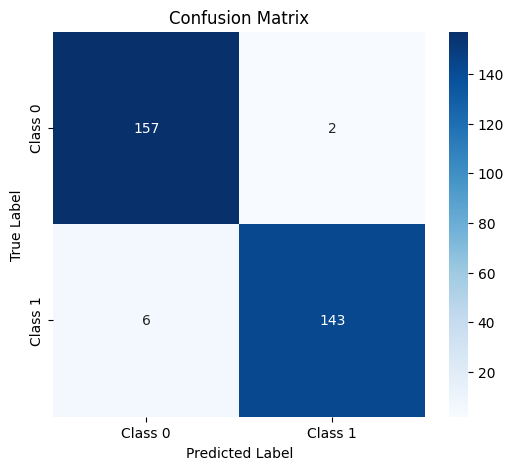

In [36]:
import shap
import lime
import lime.lime_tabular
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_val_score
from sklearn.metrics import confusion_matrix

# **1. Compute Confusion Matrix**
conf_matrix_finetuned = confusion_matrix(y_test, test_final_preds_finetuned)

# Plot Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix_finetuned, annot=True, fmt="d", cmap="Blues", xticklabels=["Class 0", "Class 1"], yticklabels=["Class 0", "Class 1"])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

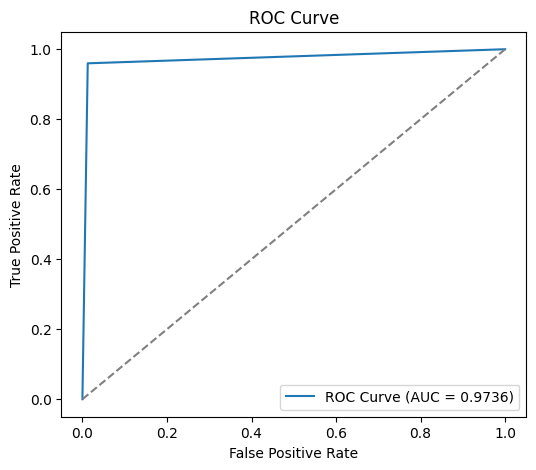

In [37]:
# ** 2. Compute ROC Curve**
plt.figure(figsize=(6, 5))
plt.plot(fpr_finetuned, tpr_finetuned, label=f"ROC Curve (AUC = {roc_auc_finetuned:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")  # Diagonal line (random guessing)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [38]:
from sklearn.model_selection import StratifiedKFold

# **Use StratifiedKFold with shuffle**
cv_strategy = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)  # 10-Fold CV with Shuffling

# **Compute Cross-Validation Scores**
cv_scores = cross_val_score(fusion_model_calibrated, X_train_poly, y_train_balanced, cv=cv_strategy, scoring='accuracy', n_jobs=-1)

# **Compute Mean & Standard Deviation**
cv_mean = np.mean(cv_scores)
cv_std = np.std(cv_scores)

# **Store & Display Results**
cv_results = pd.DataFrame([{
    'Model': "Final Fusion Model (Calibrated + Shuffled 10-Fold CV)",
    '10-Fold CV Mean Accuracy': cv_mean,
    '10-Fold CV Std Dev': cv_std
}])

In [39]:
# Print Summary
print("\n **Final Fusion Model - 10K Cross-Validation Results**:")
print(cv_results)


 **Final Fusion Model - 10K Cross-Validation Results**:
                                               Model  \
0  Final Fusion Model (Calibrated + Shuffled 10-F...   

   10-Fold CV Mean Accuracy  10-Fold CV Std Dev  
0                  0.992053            0.006489  


In [40]:
!pip install ace_tools

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [14:29:48] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



 XGBoost Model Accuracy: 0.8214


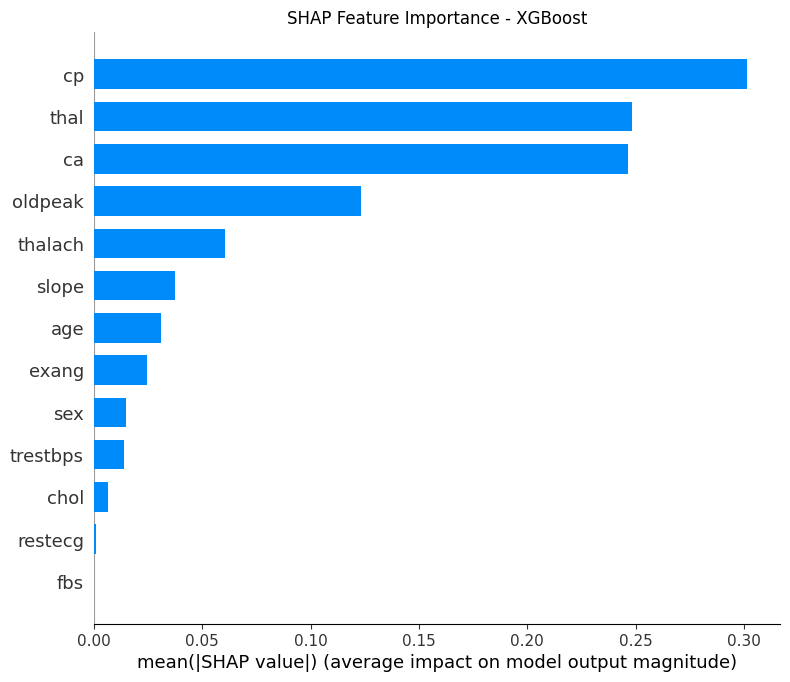

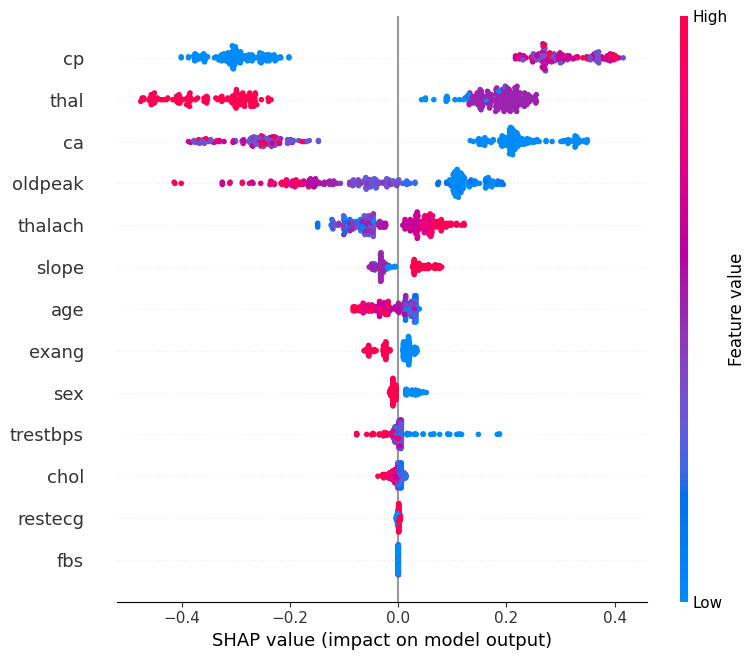

In [43]:
import shap
import xgboost as xgb
import lightgbm as lgb
import matplotlib.pyplot as plt
from tpot import TPOTClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# **Split dataset into train and test**
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# **Train XGBoost Model**
xgb_model = xgb.XGBClassifier(
    use_label_encoder=False, eval_metric='logloss',
    max_depth=3, learning_rate=0.01, n_estimators=100,
    reg_alpha=5.0, reg_lambda=6.0, subsample=0.7, colsample_bytree=0.7,
    random_state=42,
    enable_categorical=False # Explicitly disable native categorical feature handling
)
xgb_model.fit(X_train, y_train)

# **Evaluate XGBoost Model**
y_pred_xgb = xgb_model.predict(X_test)
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
print(f"\n XGBoost Model Accuracy: {accuracy_xgb:.4f}")

#  **SHAP Explainer for XGBoost**
explainer_xgb = shap.Explainer(xgb_model, X_train, feature_perturbation="tree_path_dependent")
shap_values_xgb = explainer_xgb(X_test)

#  **SHAP Summary Plot (Feature Importance)**
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_xgb, X_test, plot_type="bar", show=False)
plt.title("SHAP Feature Importance - XGBoost")
plt.show()

#  **SHAP Beeswarm Plot for Global Explanation**
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_xgb, X_test)
plt.show()

[LightGBM] [Info] Number of positive: 377, number of negative: 340
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000163 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 350
[LightGBM] [Info] Number of data points in the train set: 717, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.525802 -> initscore=0.103300
[LightGBM] [Info] Start training from score 0.103300
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[

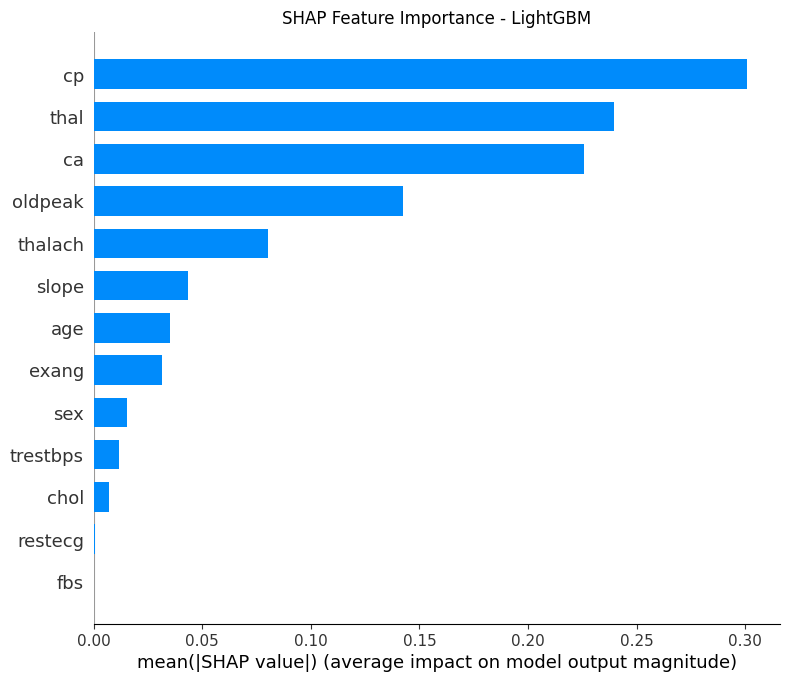

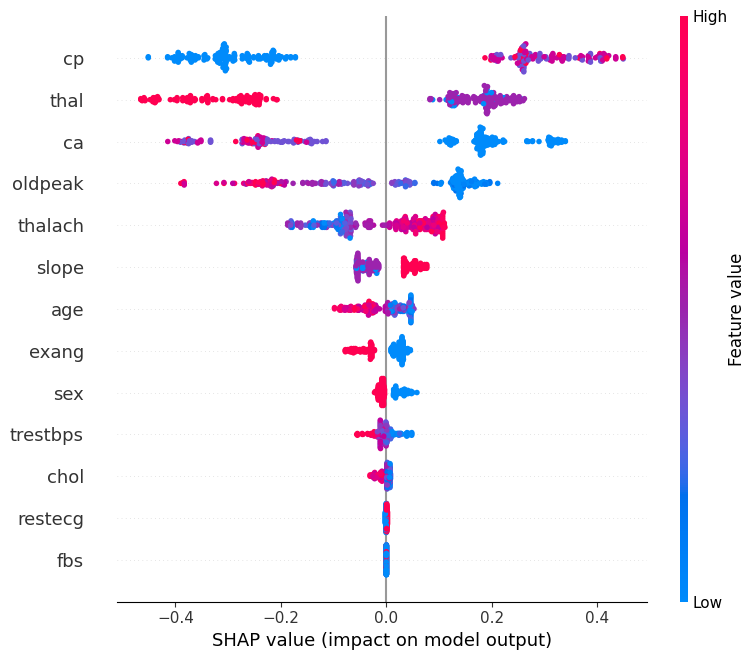

In [44]:
#  **Train LightGBM Model**
lgbm_model = lgb.LGBMClassifier(
    max_depth=3, learning_rate=0.01, n_estimators=100,
    reg_alpha=5.0, reg_lambda=6.0, subsample=0.7, colsample_bytree=0.7,
    random_state=42
)
lgbm_model.fit(X_train, y_train)

#  **Evaluate LightGBM Model**
y_pred_lgbm = lgbm_model.predict(X_test)
accuracy_lgbm = accuracy_score(y_test, y_pred_lgbm)
print(f"\n LightGBM Model Accuracy: {accuracy_lgbm:.4f}")

#  **SHAP Explainer for LightGBM**
explainer_lgbm = shap.Explainer(lgbm_model, X_train)
shap_values_lgbm = explainer_lgbm(X_test)

#  **SHAP Summary Plot (Feature Importance)**
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_lgbm, X_test, plot_type="bar", show=False)
plt.title("SHAP Feature Importance - LightGBM")
plt.show()

#  **SHAP Beeswarm Plot for Global Explanation**
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_lgbm, X_test)
plt.show()


 MLP Model Accuracy: 0.8442

 LIME Explanation for Sample 0


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but MLPClassifier was fitted with feature names
  warnings.warn(


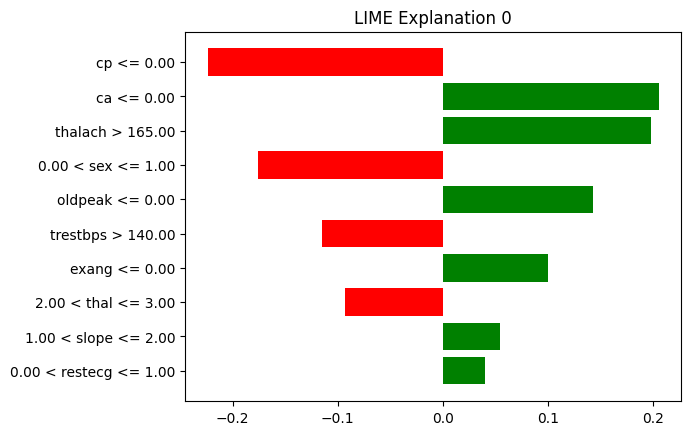

In [45]:
import lime
import lime.lime_tabular
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# ** Define Column Names for Heart Disease Dataset**
column_names = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
                "thalach", "exang", "oldpeak", "slope", "ca", "thal"]

# ** Load and Split Data**
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# ** Convert X to DataFrame for Compatibility**
X_train_df = pd.DataFrame(X_train, columns=column_names)
X_test_df = pd.DataFrame(X_test, columns=column_names)

# ** Initialize and Train MLP Model**
mlp_model = MLPClassifier(hidden_layer_sizes=(30,), activation='relu', solver='adam',
                          alpha=1.0, learning_rate='adaptive', max_iter=1000, random_state=42)
mlp_model.fit(X_train, y_train)

# ** Evaluate MLP Model**
y_pred_mlp = mlp_model.predict(X_test)
accuracy_mlp = accuracy_score(y_test, y_pred_mlp)
print(f"\n MLP Model Accuracy: {accuracy_mlp:.4f}")

# ** Initialize LIME Explainer**
explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train_df.values,  # Training data as NumPy array
    feature_names=column_names,       # Feature names from dataset
    class_names=['No Heart Disease', 'Heart Disease'],  # Class labels
    mode='classification'              # Classification task
)

# ** Select a Sample to Explain (First Test Sample)**
sample_idx = 0  # First test sample
sample_data = X_test_df.iloc[sample_idx].values  # Extract feature values

# ** Generate LIME Explanation for MLP**
lime_exp = explainer.explain_instance(
    data_row=sample_data,          # Feature values of the sample
    predict_fn=mlp_model.predict_proba,  # MLP Model's probability prediction function
    num_features=10                # Number of top influential features to display
)

# ** Display LIME Explanation**
print(f"\n LIME Explanation for Sample {sample_idx}")
lime_exp.show_in_notebook(show_table=True)
lime_exp.as_pyplot_figure()
plt.title(f"LIME Explanation {sample_idx}")
plt.show()

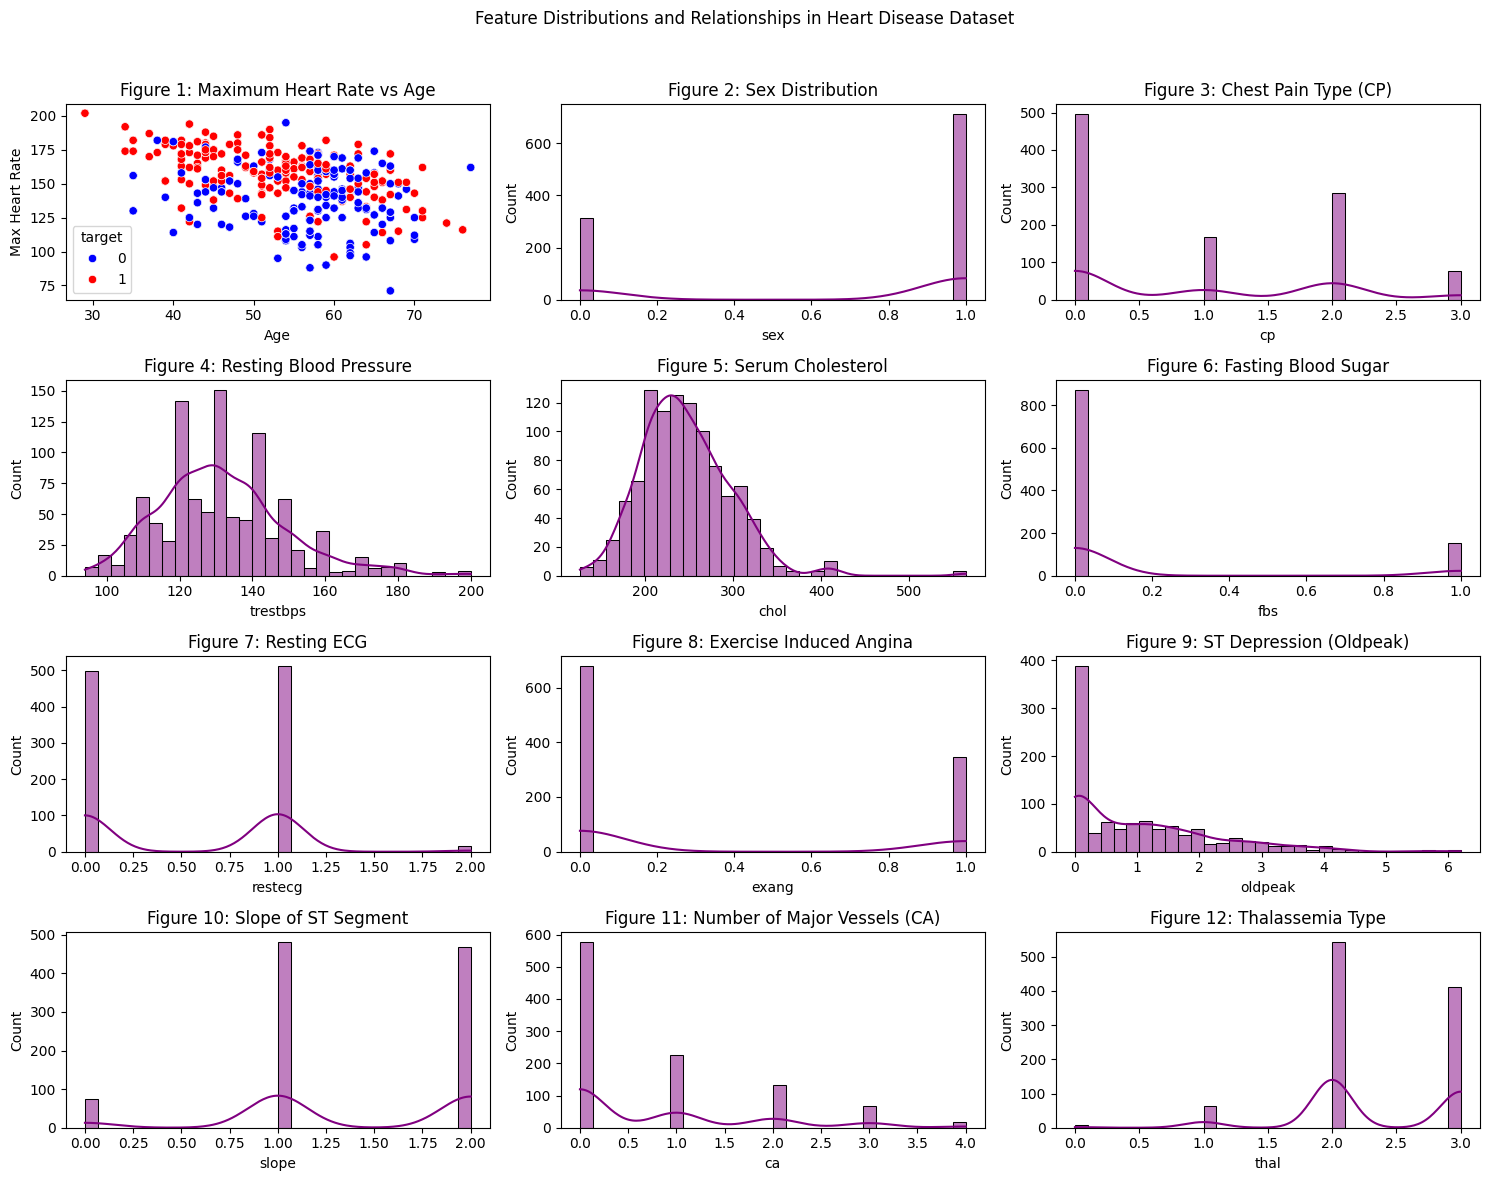

Figure saved to: /content/drive


In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

# Define the save path inside Google Drive
save_path = "/content/drive"

# Creating subplots for visualizing different attributes
fig, axes = plt.subplots(4, 3, figsize=(15, 12))
fig.suptitle("Feature Distributions and Relationships in Heart Disease Dataset")

# Scatter plot: Maximum Heart Rate vs Age colored by Heart Disease presence
sns.scatterplot(x=X['age'], y=X['thalach'], hue=y, palette=["blue", "red"], ax=axes[0, 0])
axes[0, 0].set_title("Figure 1: Maximum Heart Rate vs Age")
axes[0, 0].set_xlabel("Age")
axes[0, 0].set_ylabel("Max Heart Rate")

# Distribution plots for each feature
features = ["sex", "cp", "trestbps", "chol", "fbs", "restecg", "exang", "oldpeak", "slope", "ca", "thal"]
titles = [
    "Sex Distribution", "Chest Pain Type (CP)", "Resting Blood Pressure",
    "Serum Cholesterol", "Fasting Blood Sugar", "Resting ECG",
    "Exercise Induced Angina", "ST Depression (Oldpeak)", "Slope of ST Segment",
    "Number of Major Vessels (CA)", "Thalassemia Type"
]

# Assign each plot to a subplot
for i, (feature, title) in enumerate(zip(features, titles)):
    row, col = divmod(i + 1, 3)  # +1 to avoid overwriting the scatter plot
    sns.histplot(X[feature], kde=True, bins=30, ax=axes[row, col], color="purple")
    axes[row, col].set_title(f"Figure {i+2}: {title}")

# Adjust layout
plt.tight_layout(rect=[0, 0, 1, 0.96])

# Save figure in Google Drive
plt.savefig(save_path, dpi=300)
plt.show()

print(f"Figure saved to: {save_path}")